# Chapter 34 - The Brief and the Data

This notebook opens the Sedge Shoes case study that runs through Chapters 34 to 39 of *Marketing Mix Modelling*: a UK running-shoe retailer selling across 18 regions, asking what its £6 million of media bought last year and how next year's budget should be split.
Before fitting anything, it does what the chapter does: reads the brief, then audits the data against it.

The data come from `generate_sedge` in `mmm_book.sedge`, a deterministic generator built to behave the way Chapter 34 describes Sedge.
It has the same columns, the same scale (18 regions, 156 weeks, about £48 million of revenue and £6 million of media a year) and the same awkward patterns: Television bought in flights, Meta and YouTube planned together, Paid Search following category demand.
Because the data are synthetic, the true return of every channel is known, which lets the later notebooks, and Appendix F, check the fitted model against the truth; the chapters themselves report what the fitted model says.
Appendix F of the book prints sample rows, the variable dictionary and the full model.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from mmm_book import RANDOM_SEED
from mmm_book.plotting import mmm_style
from mmm_book.reference import national_aggregate
from mmm_book.sedge import BOOK_ANNUAL_SPEND, CHANNELS, generate_sedge

mmm_style()
pd.set_option("display.width", 120)

## The brief

The chief financial officer wants one number per channel for what last year's media bought, and the four questions in the chapter follow from that.
How much incremental revenue did each channel generate?
How certain are those estimates?
Where is the next pound likely to generate the greatest return?
How should the £6 million be allocated next year?
Answering any of them responsibly starts with understanding what the data contain, not with fitting a model.

In [2]:
df = generate_sedge(seed=RANDOM_SEED)
print(f"rows: {len(df):,}, columns: {df.shape[1]}")
print(
    f"regions: {df['region'].nunique()}, weeks per region: "
    f"{df.groupby('region')['week'].nunique().unique()}"
)
print(f"dates: {df['date'].min().date()} to {df['date'].max().date()}")
df.head()

rows: 2,808, columns: 26
regions: 18, weeks per region: [156]
dates: 2022-01-03 to 2024-12-23


,region,week,date,tv_grps,tv_spend,search_spend,search_impr,search_brand_spend,search_generic_impr,meta_spend,...,price,promo_depth,distribution,stock,temperature,rainfall,launch,category_search,brand_search_volume,revenue
0,region_0,0,2022-01-03,1.357529,543.011577,1713.208352,61414.098122,430.133436,53914.803980,1957.982716,...,95.645065,0.0,0.857249,0.976747,7.051536,16.713492,0.0,115.464632,1296.974133,49409.824851
1,region_0,1,2022-01-10,0.472646,189.058256,1738.162936,64417.344500,482.148300,55116.664508,2536.663270,...,94.307622,0.0,0.820638,0.970359,5.772300,13.019635,0.0,122.013625,1478.896337,54159.825445
2,region_0,2,2022-01-17,0.675849,270.339560,1723.640631,55367.890846,551.908477,45188.670617,2883.827268,...,92.767658,0.0,0.797674,0.970108,7.436365,14.437451,0.0,111.108780,1793.322259,57838.588418
3,region_0,3,2022-01-24,1.322385,528.953862,1801.508069,58286.800971,588.108605,47228.578608,3114.385062,...,91.158417,0.0,0.892731,0.965380,3.646212,31.264931,0.0,115.737977,1968.290102,56578.021829
4,region_0,4,2022-01-31,3.042004,1216.801488,2160.441302,72532.121521,659.924525,60132.519396,2114.374442,...,98.283456,0.0,0.861946,0.981381,4.237600,18.121342,0.0,117.342322,2093.743912,55461.570349


## Step 1 - the variables

Chapter 34 lists the media variables (Paid Search, Meta, YouTube, Television and OOH, each with its activity measure and spend), the controls (promotion depth, average selling price, distribution, stock availability, rainfall, temperature, product launches and seasonality), a broad category search index as a demand control, and branded Sedge search volume, which the core model leaves out.
The panel carries all of them.
Paid Search spend is also split into its brand part and its generic impressions, because Chapter 35 needs that split.

In [3]:
groups = {
    "media": [
        "tv_grps",
        "tv_spend",
        "search_spend",
        "search_impr",
        "search_brand_spend",
        "search_generic_impr",
        "meta_spend",
        "meta_impr",
        "youtube_spend",
        "youtube_reach",
        "youtube_frequency",
        "ooh_spend",
        "ooh_impr",
    ],
    "controls": [
        "price",
        "promo_depth",
        "distribution",
        "stock",
        "temperature",
        "rainfall",
        "launch",
        "category_search",
    ],
    "left out of the core model": ["brand_search_volume"],
    "outcome": ["revenue"],
}
for name, cols in groups.items():
    print(f"{name}: {', '.join(cols)}")

media: tv_grps, tv_spend, search_spend, search_impr, search_brand_spend, search_generic_impr, meta_spend, meta_impr, youtube_spend, youtube_reach, youtube_frequency, ooh_spend, ooh_impr
controls: price, promo_depth, distribution, stock, temperature, rainfall, launch, category_search
left out of the core model: brand_search_volume
outcome: revenue


## Step 2 - missing values and implausible ranges

The next check is for gaps and for values that make no business sense: negative spend, a distribution share above one, a price nobody pays for running shoes.

In [4]:
print("missing values:", int(df.isna().sum().sum()))
audit = [
    "tv_grps",
    "search_spend",
    "meta_spend",
    "youtube_spend",
    "ooh_spend",
    "price",
    "promo_depth",
    "distribution",
    "stock",
    "temperature",
    "rainfall",
    "category_search",
    "revenue",
]
df[audit].describe().T[["mean", "std", "min", "max"]].round(2)

missing values: 0


,mean,std,min,max
tv_grps,3.74,5.18,0.34,36.75
search_spend,1495.73,479.98,308.12,3494.08
meta_spend,1602.56,548.05,544.79,4224.16
youtube_spend,854.70,270.56,256.07,2228.25
ooh_spend,961.54,654.69,217.96,6141.21
price,93.62,4.52,76.25,107.60
promo_depth,0.03,0.07,0.00,0.30
distribution,0.85,0.03,0.75,1.00
stock,0.96,0.03,0.81,1.00
temperature,10.83,4.74,-1.49,23.79


Nothing needs cleaning.
Spend and GRPs are never negative, distribution and stock are shares between about 0.75 and 1, the average selling price sits around £94 a pair (a £95 list price pulled down a little in promotion weeks), promotion depth is zero in most weeks and between 10 and 30 per cent off when a promotion runs, and revenue is comfortably positive.
A clean audit is not the same as clean data, as Chapter 35 will show, but it is the right place to start.

## Step 3 - reconciling to the book's totals

The national series used later must be an exact sum of the regions, and the annual totals must match the figures the chapter prints: £1.40m Paid Search, £1.50m Meta, £0.80m YouTube, £1.40m Television and £0.90m OOH, £6.00m in all, against about £48 million of revenue.

In [5]:
nat = national_aggregate(df)
assert np.allclose(nat["revenue"].to_numpy(), df.groupby("week")["revenue"].sum().to_numpy())

years = df["week"].nunique() / 52
spend_col = {
    "tv": "tv_spend",
    "search": "search_spend",
    "meta": "meta_spend",
    "youtube": "youtube_spend",
    "ooh": "ooh_spend",
}
totals = pd.DataFrame(
    {
        "book (GBPm)": {ch: BOOK_ANNUAL_SPEND[ch] / 1e6 for ch in CHANNELS},
        "panel (GBPm)": {ch: df[spend_col[ch]].sum() / years / 1e6 for ch in CHANNELS},
    }
)
totals.loc["total"] = totals.sum()
print(totals.round(2))
print(f"\naverage annual revenue: {df['revenue'].sum() / years / 1e6:.1f}m")

         book (GBPm)  panel (GBPm)
tv               1.4           1.4
search           1.4           1.4
meta             1.5           1.5
youtube          0.8           0.8
ooh              0.9           0.9
total            6.0           6.0

average annual revenue: 47.9m


## Step 4 - the media histories

The chapter's team plots the media histories before anything else, and the plots set expectations.
The shaded bands mark the spring race season (mid-March to late April) and the run-up to Christmas.

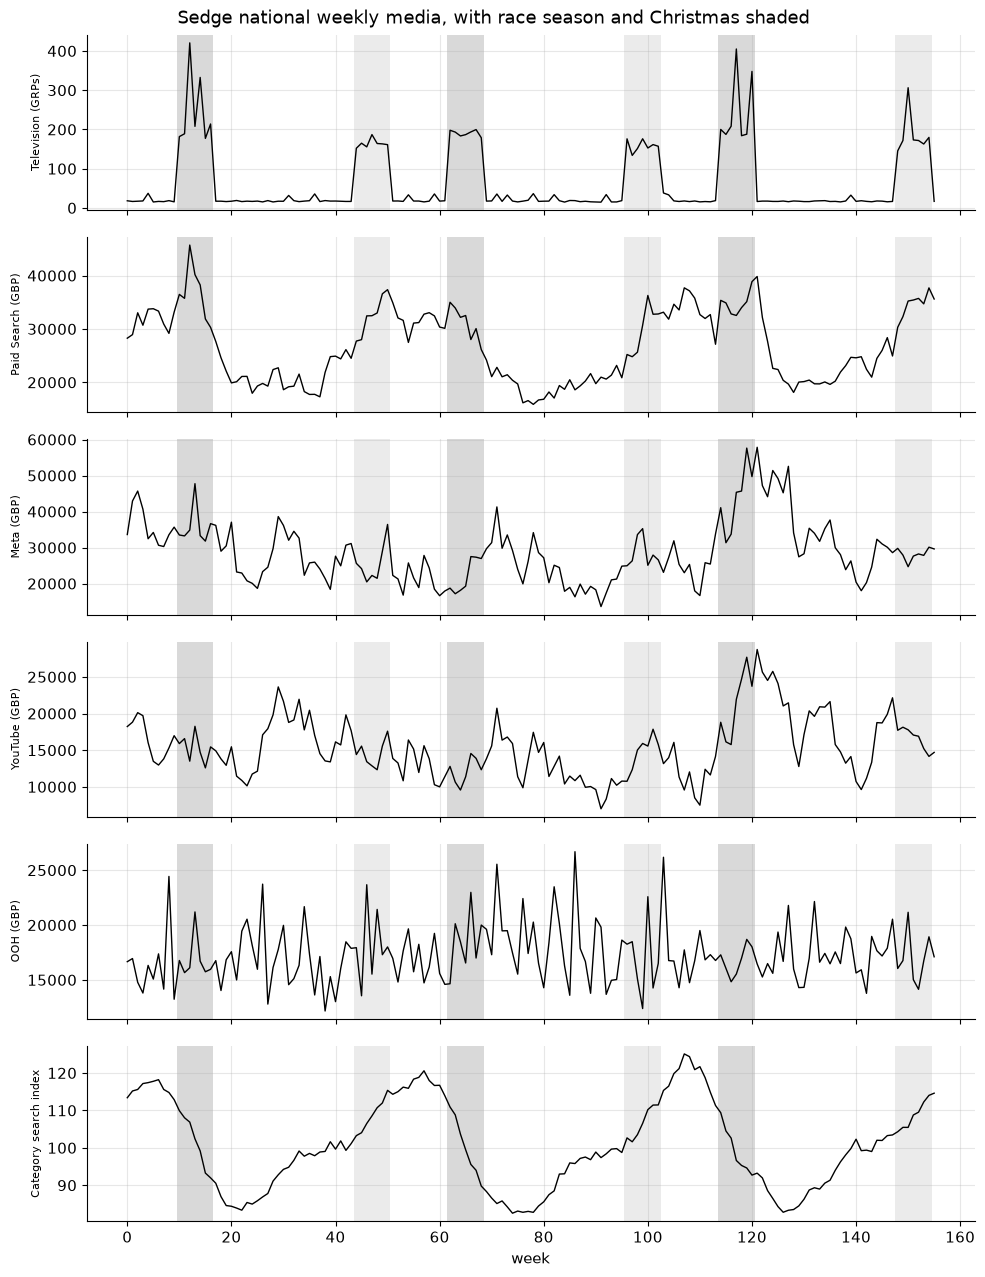

In [6]:
woy = nat["week"] % 52
race = woy.between(10, 16)
xmas = woy.between(44, 50)

series = {
    "Television (GRPs)": nat["tv_grps"],
    "Paid Search (GBP)": nat["search_spend"],
    "Meta (GBP)": nat["meta_spend"],
    "YouTube (GBP)": nat["youtube_spend"],
    "OOH (GBP)": nat["ooh_spend"],
    "Category search index": df.groupby("week")["category_search"].mean(),
}
fig, axes = plt.subplots(len(series), 1, figsize=(10, 13), sharex=True)
for ax, (name, s) in zip(axes, series.items(), strict=True):
    for mask, colour in ((race, "0.85"), (xmas, "0.92")):
        for w in nat["week"][mask]:
            ax.axvspan(w - 0.5, w + 0.5, color=colour, lw=0)
    ax.plot(nat["week"], s, color="k", lw=1)
    ax.set_ylabel(name, fontsize=8)
axes[-1].set_xlabel("week")
fig.suptitle("Sedge national weekly media, with race season and Christmas shaded")
fig.tight_layout()

Television is bursty and concentrated in the shaded weeks, so it moves with seasonality and with the promotions that cluster in the same weeks.
Meta and YouTube rise and fall together, because they are planned from one paid-social budget.
Paid Search follows the category search index.
OOH bounces around from region to region with little national pattern, apart from one regional push in mid-2023 that Chapter 35 explains.

## Step 5 - the correlations the chapter reports

Chapter 34 gives three numbers: Meta and YouTube spend correlate 0.85 nationally and 0.76 across the geo-week panel, and Paid Search spend correlates 0.72 with the category search index.

In [7]:
cat_nat = df.groupby("week")["category_search"].mean().to_numpy()
print(
    f"Meta and YouTube, national weekly:  "
    f"{np.corrcoef(nat['meta_spend'], nat['youtube_spend'])[0, 1]:.2f}"
)
print(
    f"Meta and YouTube, region-week panel: "
    f"{np.corrcoef(df['meta_spend'], df['youtube_spend'])[0, 1]:.2f}"
)
print(f"Paid Search and the category index:  {np.corrcoef(nat['search_spend'], cat_nat)[0, 1]:.2f}")

spend = nat[[spend_col[ch] for ch in CHANNELS]].set_axis(CHANNELS, axis=1)
print("\nnational weekly spend correlations")
print(spend.corr().round(2))

Meta and YouTube, national weekly:  0.85
Meta and YouTube, region-week panel: 0.76
Paid Search and the category index:  0.72

national weekly spend correlations
           tv  search  meta  youtube   ooh
tv       1.00    0.59  0.19     0.10  0.01
search   0.59    1.00  0.19     0.05 -0.10
meta     0.19    0.19  1.00     0.85 -0.03
youtube  0.10    0.05  0.85     1.00 -0.01
ooh      0.01   -0.10 -0.03    -0.01  1.00


These are the figures the chapter prints.
Television and Paid Search also move together (both follow the season), which is one more reason Chapter 35 controls for the calendar so carefully.
Two channels moving together is not a modelling problem yet, but it predicts one: with Meta and YouTube this close, the data may know how much the pair earned without knowing how to split it.

OOH is the opposite case.
A simple way to see why the chapter expects it to be the easiest channel to identify is to ask how much of each channel's variation is between regions in the same week, which is variation the national plan did not create.

In [8]:
def regional_share(col):
    within_week = df.groupby("week")[col].transform("mean")
    rel = df[col] / within_week
    return float(rel.var() / (df[col] / df[col].mean()).var())


print("share of variation that is regional (between regions within a week)")
for ch in CHANNELS:
    print(f"  {ch:<8}{regional_share(spend_col[ch]):.2f}")

share of variation that is regional (between regions within a week)
  tv      0.05
  search  0.41
  meta    0.20
  youtube 0.25
  ooh     0.82


OOH and Paid Search vary most from region to region, Television least.
Regional variation that the national plan did not cause is exactly what a regional model can use to tell channels apart.

## Step 6 - the causal graph and branded search

The chapter's causal graph has television, Meta and YouTube raising branded search, which makes branded search volume a mediator: controlling for it would block part of the very effect the model is trying to measure.
The data show the same thing.
Branded search volume moves with the upper-funnel channels, so it stays out of the core model's controls, while the broad category index stays in as a demand control.

In [9]:
brand = df.groupby("week")["brand_search_volume"].sum()
upper = {
    "tv_grps": nat["tv_grps"],
    "meta_spend": nat["meta_spend"],
    "youtube_spend": nat["youtube_spend"],
}
for name, s in upper.items():
    print(f"brand search volume vs {name:<14}{np.corrcoef(brand, s)[0, 1]:.2f}")
print(f"brand search volume vs category index   {np.corrcoef(brand, cat_nat)[0, 1]:.2f}")

brand search volume vs tv_grps       0.76
brand search volume vs meta_spend    0.48
brand search volume vs youtube_spend 0.34
brand search volume vs category index   0.20


## Takeaway

The audit found a complete panel with sensible ranges that reconciles to the book's totals, and it found the patterns that will shape everything after it.
Television moves with the calendar.
Meta and YouTube move together.
Paid Search follows demand, and part of it is brand search that collects demand other channels created.
OOH varies regionally and should be the easiest channel to pin down.
None of this needed a model, only arithmetic and a few plots, and it is the list of ways the answer could go wrong that Chapter 35's first model will be checked against.